Gradient Descent Final Loss: 0.09723367542028427
SGD Final Loss: 0.07602918148040771
Momentum Final Loss: 0.08608303219079971
Adam Final Loss: 0.07949250936508179


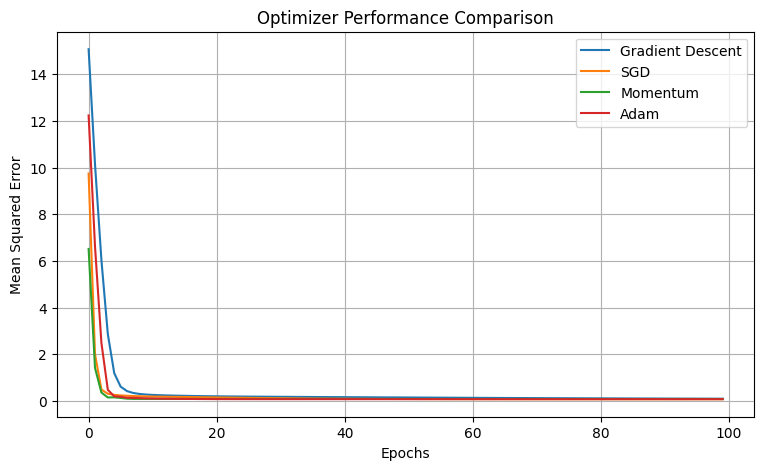

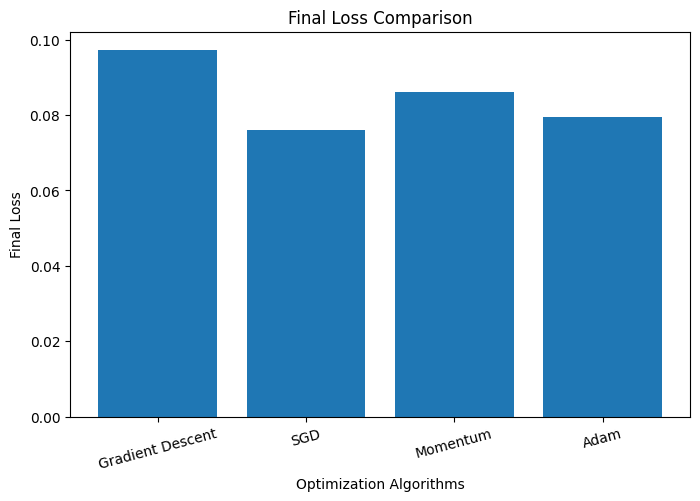

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

np.random.seed(42)
tf.random.set_seed(42)

# 1. Generate sample dataset
X = np.linspace(
    -2, 2, 200
).reshape(-1, 1).astype("float32")

y = (
    3 * X + 2
    + np.random.normal(0, 0.3, X.shape)
).astype("float32")

# 2. Define optimizers
optimizers = {
    "Gradient Descent": lambda: tf.keras.optimizers.SGD(
        learning_rate=0.05
    ),

    "SGD": lambda: tf.keras.optimizers.SGD(
        learning_rate=0.01
    ),

    "Momentum": lambda: tf.keras.optimizers.SGD(
        learning_rate=0.01,
        momentum=0.9
    ),

    "Adam": lambda: tf.keras.optimizers.Adam(
        learning_rate=0.01
    )
}

histories = {}
final_losses = {}

# 3. Train models using different optimizers
for name, optimizer_function in optimizers.items():

    tf.keras.backend.clear_session()

    tf.keras.utils.set_random_seed(123)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(1,)),
        tf.keras.layers.Dense(
            16,
            activation="relu"
        ),
        tf.keras.layers.Dense(1)
    ])

    model.compile(
        optimizer=optimizer_function(),
        loss="mse"
    )

    batch_size = (
        200 if name == "Gradient Descent"
        else 16
    )

    history = model.fit(
        X,
        y,
        epochs=100,
        batch_size=batch_size,
        verbose=0
    )

    histories[name] = history.history["loss"]

    final_losses[name] = history.history["loss"][-1]

    print(
        name,
        "Final Loss:",
        final_losses[name]
    )

# 4. Plot loss comparison
plt.figure(figsize=(9, 5))

for name, losses in histories.items():

    plt.plot(
        losses,
        label=name
    )

plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")

plt.title(
    "Optimizer Performance Comparison"
)

plt.legend()
plt.grid()

plt.show()

# 5. Plot final loss
plt.figure(figsize=(8, 5))

plt.bar(
    list(final_losses.keys()),
    list(final_losses.values())
)

plt.xlabel("Optimization Algorithms")
plt.ylabel("Final Loss")

plt.title(
    "Final Loss Comparison"
)

plt.xticks(rotation=15)

plt.show()